# 03 — Delivery Failure

Where does delivery fail? Which customer states and which sellers have the highest late rates, and do orders that cross state lines arrive late more often?

Late = delivered after the estimated date. Notebook 01 showed that late orders get worse reviews; this notebook looks for where lateness happens. Monetary values are in BRL (R$).

## Data Setup

In [1]:
# Connect to the local ecommerce database
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg://localhost/ecommerce")

In [2]:
# Shared chart style: dark theme and font for every chart in this notebook
import matplotlib.pyplot as plt

# Colour constants: change a colour here and every chart follows
BG = "#1a1a19"          # background
TEXT = "#f0efec"        # titles and key labels
TEXT_MUTED = "#c3c2b7"  # axis labels, ticks and annotations
BLUE = "#3987e5"        # main series / on time
ORANGE = "#d95926"      # problem series / late

# rcParams holds matplotlib's global settings
plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "savefig.facecolor": BG,
    "text.color": TEXT,
    "axes.labelcolor": TEXT_MUTED,
    "axes.edgecolor": TEXT_MUTED,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "grid.color": "#383835",
    "font.family": ["Avenir Next", "Helvetica Neue", "DejaVu Sans"],  # first installed font is used
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Order Dataset

Grain: one row per order, with the customer's state and the delivery dates.

In [3]:
# One row per order: customer state, status and delivery dates
order_query = """
SELECT
    orders.order_id,
    customers.customer_state,
    orders.order_status,
    orders.order_delivered_customer_date,
    orders.order_estimated_delivery_date
FROM orders
JOIN customers
    ON orders.customer_id = customers.customer_id
"""

orders_df = pd.read_sql(order_query, engine)
orders_df.shape

(99441, 5)

In [4]:
# Delivery status, same definition as notebook 01 and sql/analysis.sql
delivered = orders_df["order_delivered_customer_date"]
estimated = orders_df["order_estimated_delivery_date"]

orders_df["delivery_status"] = "Not Delivered"
orders_df.loc[delivered.notna() & (delivered <= estimated), "delivery_status"] = "On Time"
orders_df.loc[delivered.notna() & (delivered > estimated), "delivery_status"] = "Late"

orders_df["delivery_status"].value_counts()

delivery_status
On Time          88649
Late              7827
Not Delivered     2965
Name: count, dtype: int64

## Late Delivery by State

Where does delivery fail? Do customers in some states wait longer than the estimate far more often?

Late rate = share of **delivered** orders that arrived after the estimate. Grain: one row per customer state. States with very few orders are dropped, because a rate from 40 orders is mostly luck.

In [5]:
# Late rate per customer state, delivered orders only
delivered_orders = orders_df[orders_df["delivery_status"] != "Not Delivered"].copy()
delivered_orders["is_late"] = delivered_orders["delivery_status"] == "Late"  # True / False per order

state_late = delivered_orders.groupby("customer_state").agg(
    orders=("is_late", "count"),      # how many delivered orders
    late_rate=("is_late", "mean"),   # average of True/False = share that is late
)

# Tiny states give unreliable rates: keep states with enough orders
state_late = state_late[state_late["orders"] >= 200]
state_late["late_rate"] = state_late["late_rate"] * 100
state_late = state_late.sort_values("late_rate", ascending=False)
print(state_late.round(1))

                orders  late_rate
customer_state                   
AL                 397       23.9
MA                 717       19.7
PI                 476       16.0
CE                1279       15.3
SE                 335       15.2
BA                3256       14.0
RJ               12353       13.5
TO                 274       12.8
PA                 946       12.4
ES                1995       12.2
MS                 701       11.6
PB                 517       11.0
PE                1593       10.8
RN                 474       10.8
SC                3547        9.8
GO                1957        8.2
RS                5344        7.1
DF                2080        7.1
MT                 886        6.8
SP               40495        5.9
MG               11355        5.6
PR                4923        5.0
RO                 243        2.9


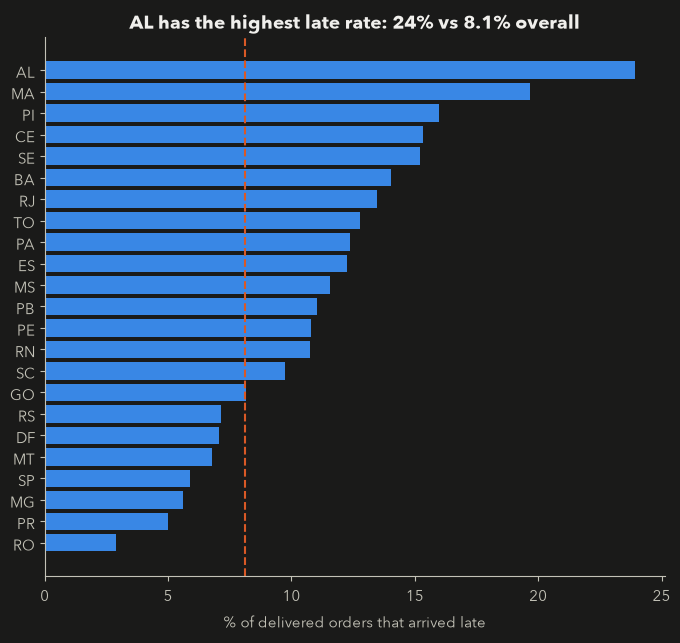

In [6]:
# Late rate by state (worst first), with the overall late rate as a reference line
overall_late = delivered_orders["is_late"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(state_late.index, state_late["late_rate"], color=BLUE)
ax.invert_yaxis()  # worst state on top
ax.axvline(overall_late, color=ORANGE, linestyle="--")  # states right of this line are worse than average
ax.set_xlabel("% of delivered orders that arrived late")
ax.set_title(f"{state_late.index[0]} has the highest late rate: {state_late['late_rate'].iloc[0]:.0f}% vs {overall_late:.1f}% overall")
plt.show()

**Finding**

- **Late rates vary widely by state:** from 2.9% (RO) to **23.9% (AL)**, about 3x the overall 8.1%.
- **The worst states are in the Northeast** (AL, MA, PI, CE, SE, BA, 14-24% late); the big southern states do best (SP 5.9%, MG 5.6%, PR 5.0%).
- **RJ is the biggest problem by volume:** 13.5% late on 12,353 orders, nearly 1,700 late orders.
- This shows *where* lateness is higher, not *why*; the last section checks one possible reason, cross-state shipping.

## Late Delivery by Seller

Is lateness a few weak sellers, or spread evenly? And do sellers with high late rates also get worse reviews?

An order can contain items from several sellers, so the grain is one row per **(order, seller)** pair. A seller's late rate = share of their delivered orders that arrived after the estimate. Sellers with few deliveries are dropped, as with small states.

In [7]:
# One row per (order, seller) for delivered orders, with the order's latest review score
seller_query = """
WITH seller_orders AS (
    -- one row per (order, seller) pair
    SELECT DISTINCT
        order_id,
        seller_id
    FROM order_items
),
ranked_reviews AS (
    -- number each order's reviews, newest first (same pattern as notebook 01)
    SELECT
        order_id,
        review_score,
        ROW_NUMBER() OVER (
            PARTITION BY order_id
            ORDER BY review_creation_date DESC, review_answer_timestamp DESC
        ) AS review_rank
    FROM order_reviews
)
SELECT
    seller_orders.seller_id,
    seller_orders.order_id,
    orders.order_delivered_customer_date,
    orders.order_estimated_delivery_date,
    ranked_reviews.review_score
FROM seller_orders
JOIN orders
    ON seller_orders.order_id = orders.order_id
LEFT JOIN ranked_reviews
    ON seller_orders.order_id = ranked_reviews.order_id
    AND ranked_reviews.review_rank = 1
WHERE orders.order_delivered_customer_date IS NOT NULL
"""

seller_orders_df = pd.read_sql(seller_query, engine)
seller_orders_df.shape

(97817, 5)

In [8]:
# Grain check: rows are (order, seller) pairs, so rows >= distinct orders
print("rows:", len(seller_orders_df))
print("distinct orders:", seller_orders_df["order_id"].nunique())

rows: 97817
distinct orders: 96476


In [9]:
# Per-seller late rate and average review
seller_orders_df["is_late"] = seller_orders_df["order_delivered_customer_date"] > seller_orders_df["order_estimated_delivery_date"]

seller_stats = seller_orders_df.groupby("seller_id").agg(
    deliveries=("is_late", "count"),
    late_rate=("is_late", "mean"),
    avg_review=("review_score", "mean"),  # orders with no review are skipped automatically
)

# Keep sellers with enough deliveries for a stable rate
seller_stats = seller_stats[seller_stats["deliveries"] >= 50]
seller_stats["late_rate"] = seller_stats["late_rate"] * 100
print(len(seller_stats), "sellers kept")
print(seller_stats.describe().round(1))

425 sellers kept
       deliveries  late_rate  avg_review
count       425.0      425.0       425.0
mean        174.1        7.8         4.1
std         232.0        4.8         0.3
min          50.0        0.0         2.4
25%          67.0        4.4         4.0
50%          97.0        6.8         4.2
75%         168.0       10.4         4.3
max        1819.0       30.1         4.8


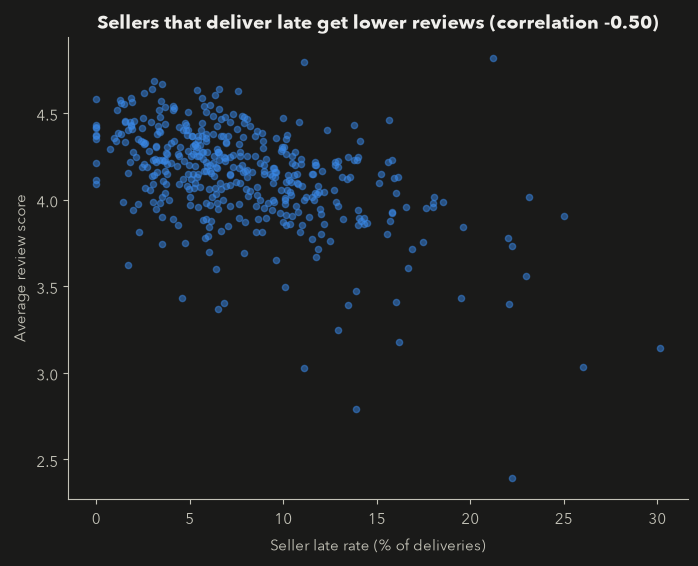

Correlation: -0.50


In [10]:
# Do sellers with a higher late rate get lower average reviews?

# Correlation: -1 to +1, 0 = no linear link
correlation = seller_stats["late_rate"].corr(seller_stats["avg_review"])

fig, ax = plt.subplots(figsize=(8, 6))

# One dot per seller; transparency shows where dots overlap
ax.scatter(seller_stats["late_rate"], seller_stats["avg_review"], s=20, color=BLUE, alpha=0.5)

ax.set_xlabel("Seller late rate (% of deliveries)")
ax.set_ylabel("Average review score")

ax.set_title(f"Sellers that deliver late get lower reviews (correlation {correlation:.2f})")
plt.show()

print(f"Correlation: {correlation:.2f}")

**Finding**

- **425 sellers had 50+ deliveries and were kept**; sellers with fewer are too small to judge a rate.
- **Late rates differ a lot between sellers:** the median is 6.8%, the top quarter is above 10.4%, and the worst seller is at 30.1%.
- **Sellers with higher late rates tend to have lower reviews:** the correlation is **-0.50**, a moderate negative link.
- This is an association, not proof that lateness causes the lower scores; slow delivery, product quality and distance can all play a part.

## Same State or Across States?

Do orders that cross state lines arrive late more often? Many orders ship from a seller in one state to a customer in another. "Same state" is a simple stand-in for a shorter trip; actual distance is not measured.

Grain: one row per (order, seller) pair, delivered orders only.

In [11]:
# One row per (order, seller) for delivered orders, with both states
route_query = """
WITH seller_orders AS (
    -- one row per (order, seller) pair
    SELECT DISTINCT
        order_id,
        seller_id
    FROM order_items
)
SELECT
    seller_orders.order_id,
    sellers.seller_state,
    customers.customer_state,
    orders.order_delivered_customer_date,
    orders.order_estimated_delivery_date
FROM seller_orders
JOIN orders
    ON seller_orders.order_id = orders.order_id
JOIN customers
    ON orders.customer_id = customers.customer_id
JOIN sellers
    ON seller_orders.seller_id = sellers.seller_id
WHERE orders.order_delivered_customer_date IS NOT NULL
"""

route_df = pd.read_sql(route_query, engine)
route_df.head()

,order_id,seller_state,customer_state,order_delivered_customer_date,order_estimated_delivery_date
0,00018f77f2f0320c557190d7a144bdd3,SP,SP,2017-05-12 16:04:24,2017-05-15
1,000229ec398224ef6ca0657da4fc703e,MG,MG,2018-01-22 13:19:16,2018-02-05
2,00042b26cf59d7ce69dfabb4e55b4fd9,PR,SP,2017-03-01 16:42:31,2017-03-17
3,00048cc3ae777c65dbb7d2a0634bc1ea,SP,MG,2017-05-22 13:44:35,2017-06-06
4,00054e8431b9d7675808bcb819fb4a32,SP,SP,2017-12-18 22:03:38,2018-01-04


In [12]:
# Late flag, and whether seller and customer are in the same state
route_df["is_late"] = route_df["order_delivered_customer_date"] > route_df["order_estimated_delivery_date"]
route_df["route"] = (route_df["seller_state"] == route_df["customer_state"]).map({True: "Same state", False: "Different state"})
route_df["route"].value_counts()

route
Different state    62634
Same state         35183
Name: count, dtype: int64

In [13]:
# Late rate for same-state vs different-state deliveries
route_late = route_df.groupby("route").agg(
    orders=("is_late", "count"),
    late_rate=("is_late", "mean"),
)
route_late["late_rate"] = route_late["late_rate"] * 100
print(route_late.round(1))

                 orders  late_rate
route                             
Different state   62634        9.2
Same state        35183        6.0


**Finding**

- **Orders that cross state lines are late more often:** 9.2% vs 6.0% for same-state orders (62,634 vs 35,183 orders), about 1.5x.
- **Most orders cross states:** about 64% of (order, seller) pairs (62,634 of 97,817).
- **Limit:** same-state is only a rough stand-in for distance, and other differences (which sellers, which states) may also play a part. This is an association; cross-state shipping is a useful feature for the prediction model.